# 03 Personalized Model: Item-Based Collaborative Filtering
Week 3 deliverable: a working personalized recommender with sample recommendation evidence and an explanation of how it differs from the popularity baseline.

**Method.** Item-item neighbourhood collaborative filtering. Two items are similar if many of the same customers bought both (cosine similarity on the binary user-item matrix). A user's score for an item is the sum of its similarities to the items the user already bought, optionally weighting recent purchases more. Everything is tuned on the **validation** block only; the test block is not used.

Run notebook 02 first: it creates `data/cleaned/`.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, data_audit as da, prepare as prep, evaluation as ev, recommender as rec

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(config.IMAGES_DIR / name, dpi=150)
    plt.show()

## 1. Load the prepared data and shared matrices

In [2]:
articles = da.load_articles()
prepared = prep.load_prepared()
exp = prep.build_experiment(prepared, articles)
K = config.TOP_K
eval_users = prep.users_with_interactions(exp.val_matrix)
print(f"users {len(exp.users):,} | items {len(exp.items):,} | train interactions {exp.train_matrix.nnz:,}")
print(f"validation users with a purchase: {len(eval_users):,}")
eval_kwargs = dict(truth=exp.val_matrix, user_positions=eval_users, item_user_share=exp.item_user_share,
                   n_items=len(exp.items), category_of_item=exp.category_of_item)

users 45,078 | items 11,916 | train interactions 735,771
validation users with a purchase: 6,698


## 2. Baseline to beat
The popularity variants from notebook 02, recomputed here so the comparison uses exactly the same data.

In [3]:
baselines = {"global popularity": None, **{f"popularity, half-life {h}d": h for h in config.HALF_LIVES_DAYS}}
base_scores = {n: prep.popularity_scores(exp.split.train, exp.items, h) for n, h in baselines.items()}
base_recs = {n: prep.recommend_popular(s, exp.train_matrix, eval_users, K) for n, s in base_scores.items()}
base_results = pd.DataFrame({n: ev.evaluate_topk(r, **eval_kwargs) for n, r in base_recs.items()}).T
display(base_results)
best_baseline = base_results[f"NDCG@{K}"].idxmax()
print("Best popularity baseline on validation:", best_baseline)
fallback_ranking = np.argsort(-base_scores[best_baseline], kind="stable")

,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
global popularity,0.0045,0.0178,0.0111,0.0013,5.6903,0.0199,0.5951,"6,698.0000"
"popularity, half-life 1d",0.0076,0.0354,0.0196,0.0012,9.1761,0.0044,0.6992,"6,698.0000"
"popularity, half-life 3d",0.0076,0.0349,0.0197,0.0012,8.2033,0.0073,0.5009,"6,698.0000"
"popularity, half-life 5d",0.0074,0.0339,0.0193,0.0012,8.1849,0.0073,0.5094,"6,698.0000"
"popularity, half-life 7d",0.0072,0.0325,0.0187,0.0012,8.0651,0.0075,0.5984,"6,698.0000"
"popularity, half-life 14d",0.0063,0.0266,0.0162,0.0012,6.9115,0.0124,0.6129,"6,698.0000"
"popularity, half-life 28d",0.0049,0.0206,0.0126,0.0013,6.1427,0.0164,0.7144,"6,698.0000"
"popularity, half-life 56d",0.0041,0.0168,0.0111,0.0013,5.8777,0.0178,0.5981,"6,698.0000"


Best popularity baseline on validation: popularity, half-life 3d


## 3. Tune the model on validation
Three choices are tuned: the similarity **shrinkage** (damps similarities that rest on few co-buyers), the number of **neighbours** kept per item, and the **recency weighting** of a user's own history (`None` treats all training purchases equally). The neighbour table is computed once per shrink value and truncated for smaller neighbour counts.

In [4]:
history = {hl: (exp.train_matrix if hl is None else
                prep.build_interaction_matrix(exp.split.train, exp.users, exp.items, "recency", half_life_days=hl))
           for hl in config.KNN_HISTORY_HALF_LIVES}
rows, tables = [], {}
for shrink in config.KNN_SHRINK:
    t0 = time.time()
    tables[shrink] = rec.build_neighbour_table(exp.train_matrix, k_max=max(config.KNN_NEIGHBOURS), shrink=shrink)
    print(f"shrink={shrink}: neighbour table built in {time.time() - t0:.0f}s")
    for k in config.KNN_NEIGHBOURS:
        model = rec.ItemKNN(tables[shrink], k)
        for hl, hist in history.items():
            recs = model.recommend(hist, eval_users, K, fallback_ranking)
            rows.append({"shrink": shrink, "neighbours": k, "history half-life (d)": hl if hl else np.nan,
                         **ev.evaluate_topk(recs, **eval_kwargs)})
grid = pd.DataFrame(rows).sort_values(f"NDCG@{K}", ascending=False).reset_index(drop=True)
display(grid.head(12))

shrink=0.0: neighbour table built in 4s
shrink=20.0: neighbour table built in 3s


,shrink,neighbours,history half-life (d),Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
0,20.0000,50,28.0000,0.0051,0.0227,0.0159,0.7258,8.9077,0.0031,0.4074,"6,698.0000"
1,20.0000,100,28.0000,0.0051,0.0227,0.0159,0.7226,8.8694,0.0032,0.4075,"6,698.0000"
2,20.0000,20,28.0000,0.0051,0.0229,0.0158,0.7256,8.9504,0.0030,0.4101,"6,698.0000"
3,20.0000,200,28.0000,0.0050,0.0225,0.0158,0.7231,8.8404,0.0034,0.4099,"6,698.0000"
4,20.0000,200,14.0000,0.0050,0.0223,0.0157,0.7728,8.9897,0.0030,0.4143,"6,698.0000"
5,20.0000,100,14.0000,0.0050,0.0220,0.0156,0.7691,9.0058,0.0030,0.4117,"6,698.0000"
6,20.0000,20,14.0000,0.0050,0.0218,0.0154,0.7660,9.0698,0.0028,0.4109,"6,698.0000"
7,20.0000,50,14.0000,0.0049,0.0219,0.0154,0.7678,9.0365,0.0029,0.4097,"6,698.0000"
8,0.0000,100,28.0000,0.0048,0.0221,0.0154,0.7849,9.2799,0.0025,0.4444,"6,698.0000"
9,0.0000,20,28.0000,0.0049,0.0220,0.0153,0.7815,9.2887,0.0025,0.4448,"6,698.0000"


Selected on validation NDCG: {'shrink': 20.0, 'neighbours': 50.0, 'history half-life (d)': 28.0}


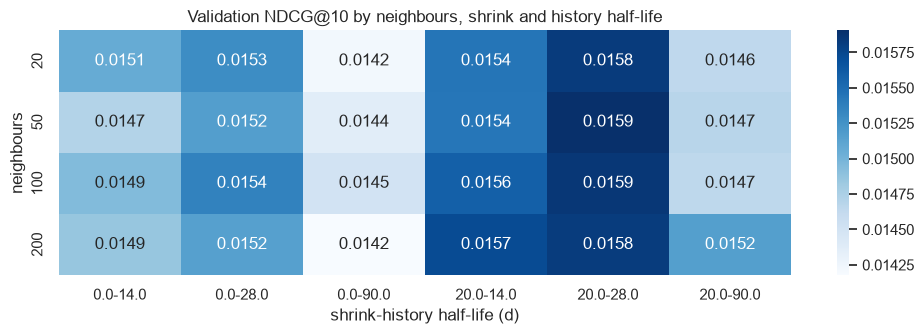

In [5]:
best = grid.iloc[0]
print("Selected on validation NDCG:", best[["shrink", "neighbours", "history half-life (d)"]].to_dict())
best_hl = None if np.isnan(best["history half-life (d)"]) else int(best["history half-life (d)"])
final_model = rec.ItemKNN(tables[float(best["shrink"])], int(best["neighbours"]))
final_history = history[best_hl]

pivot = grid.pivot_table(index="neighbours", columns=["shrink", "history half-life (d)"], values=f"NDCG@{K}")
plt.figure(figsize=(10, 3.5)); sns.heatmap(pivot, annot=True, fmt=".4f", cmap="Blues")
plt.title(f"Validation NDCG@{K} by neighbours, shrink and history half-life")
save_fig("knn_tuning_grid.png")

Check the edges of the grid: if the best value sits at the smallest or largest setting of a parameter, extend the grid in `src/config.py` and re-run, because a better value may lie beyond it.

## 4. Final model against the baselines

In [6]:
knn_recs = final_model.recommend(final_history, eval_users, K, fallback_ranking)
comparison = pd.DataFrame({
    "global popularity": base_results.loc["global popularity"],
    best_baseline: base_results.loc[best_baseline],
    "item-item CF": ev.evaluate_topk(knn_recs, **eval_kwargs),
}).T
display(comparison)
lift = comparison.loc["item-item CF", f"NDCG@{K}"] / comparison.loc[best_baseline, f"NDCG@{K}"]
print(f"NDCG@{K} of item-item CF is {lift:.2f}x the best popularity baseline on validation")

,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
global popularity,0.0045,0.0178,0.0111,0.0013,5.6903,0.0199,0.5951,"6,698.0000"
"popularity, half-life 3d",0.0076,0.0349,0.0197,0.0012,8.2033,0.0073,0.5009,"6,698.0000"
item-item CF,0.0051,0.0227,0.0159,0.7258,8.9077,0.0031,0.4074,"6,698.0000"


NDCG@10 of item-item CF is 0.81x the best popularity baseline on validation


**Reading this table.** Precision, Recall and NDCG measure whether purchases in the validation block appear in the Top-10. *Coverage* is the share of the catalogue that appears in any list, *novelty* is higher when less popular items are recommended, *mean popularity* is the average share of customers who bought the recommended items, and *category diversity* is the share of distinct product types in a list. A personalized model should raise coverage and novelty; a drop in category diversity means lists concentrate on the customer's own taste, a trade-off to discuss in the report.

## 5. Colour variants: one product, many articles
Week 1 showed that colour variants of one design share a `product_code` and crowd the top of popularity lists. Here every list is generated with 50 candidates and then collapsed to at most one article per product.

In [7]:
cand_base = prep.recommend_popular(base_scores[best_baseline], exp.train_matrix, eval_users, config.N_CANDIDATES)
cand_knn = final_model.recommend(final_history, eval_users, config.N_CANDIDATES, fallback_ranking)
dedup = {
    f"{best_baseline} (variants collapsed)": rec.diversify_by_product(cand_base, exp.product_of_item, K),
    "item-item CF (variants collapsed)": rec.diversify_by_product(cand_knn, exp.product_of_item, K),
}
dedup_results = pd.DataFrame({n: ev.evaluate_topk(r, **eval_kwargs) for n, r in dedup.items()}).T
display(pd.concat([comparison.loc[[best_baseline, "item-item CF"]], dedup_results]))
for name, recs in [(best_baseline, base_recs[best_baseline]), ("item-item CF", knn_recs)]:
    products = exp.product_of_item[recs]
    print(f"{name}: average distinct products per list = {np.mean([len(set(r)) for r in products]):.2f} of {K}")

,Precision@10,Recall@10,NDCG@10,Coverage,Novelty (bits),Mean popularity,Category diversity,users evaluated
"popularity, half-life 3d",0.0076,0.0349,0.0197,0.0012,8.2033,0.0073,0.5009,"6,698.0000"
item-item CF,0.0051,0.0227,0.0159,0.7258,8.9077,0.0031,0.4074,"6,698.0000"
"popularity, half-life 3d (variants collapsed)",0.0077,0.0354,0.0203,0.0015,9.0412,0.0045,0.7019,"6,698.0000"
item-item CF (variants collapsed),0.0042,0.0192,0.0140,0.7607,8.9963,0.0030,0.4957,"6,698.0000"


popularity, half-life 3d: average distinct products per list = 6.10 of 10
item-item CF: average distinct products per list = 7.40 of 10


## 6. Example users: recommendations with explanations
For each of five users: what they bought most recently, what the baseline would show, and what the model recommends with the purchased item that most strongly drove each recommendation.

In [8]:
rng = np.random.default_rng(config.RANDOM_SEED)
example_users = rng.choice(eval_users, 5, replace=False)
pop_list = prep.recommend_popular(base_scores[best_baseline], exp.train_matrix, example_users, K)
knn_list = rec.diversify_by_product(
    final_model.recommend(final_history, example_users, config.N_CANDIDATES, fallback_ranking), exp.product_of_item, K)
names = exp.item_names
for r, u in enumerate(example_users):
    bought = exp.split.train[exp.split.train["customer_id"] == exp.users[u]].sort_values("t_dat").tail(5)
    print("=" * 100)
    print(f"User {str(exp.users[u])[:8]} | {int(exp.train_matrix[u].nnz)} distinct items bought in training")
    print("  recent purchases:", "; ".join(names[exp.items.get_indexer(bought['article_id'])]))
    print("  popularity shows:", "; ".join(names[pop_list[r][:5]]))
    print("  item-item CF recommends:")
    for item in knn_list[r][:5]:
        why = final_model.explain(final_history, u, item, top=1)
        reason = f"because you bought {names[why[0][0]]}" if why else "popular right now (fallback)"
        print(f"    - {names[item]}  [{reason}]")

User c5a1eef5 | 57 distinct items bought in training
  recent purchases: Hilly Biker 2pk HW LS; Hercules shirt; Classic Necklace SS Phone case; Chicago; Carmen
  popularity shows: Bailey; Jade HW Skinny Denim TRS; STRONG HW seamless tights; Amelie; Amelie
  item-item CF recommends:
    - Carmen  [because you bought Carmen]
    - Timeless Cheeky Brief  [because you bought Tiger Bandeau]
    - Chicago  [because you bought Chicago]
    - Timeless Triangle Top  [because you bought Timeless Cheeky Brief]
    - Tesla Smock  Blouse  [because you bought Carmen]
User 70d67d2b | 67 distinct items bought in training
  recent purchases: ESSENTIAL LILAC TANK; Nikita dress; Lilly long shacket; ED Long leggings 2-pack; Lilly long shacket
  popularity shows: Bailey; Jade HW Skinny Denim TRS; STRONG HW seamless tights; Amelie; Amelie
  item-item CF recommends:
    - Therese tee  [because you bought Therese tee]
    - Clara jogger  [because you bought Clara jogger]
    - Antonia heavy t-shirt  [because 

## 7. Why do the recommendations differ from the baseline?

In [9]:
overlap = np.array([len(set(a) & set(b)) / K for a, b in zip(knn_recs, base_recs[best_baseline])])
top50_pop = set(np.argsort(-base_scores[best_baseline], kind="stable")[:50])
outside_top50 = np.mean([[i not in top50_pop for i in row] for row in knn_recs])
print(f"Average overlap between a user's CF list and the popularity list: {overlap.mean():.1%}")
print(f"Share of CF recommendations outside the popularity top-50: {outside_top50:.1%}")
print(f"Distinct items recommended: CF {len(np.unique(knn_recs)):,} vs popularity {len(np.unique(base_recs[best_baseline])):,}")

same_cat = np.mean([np.isin(exp.category_of_item[row], exp.category_of_item[exp.train_matrix[u].indices]).mean()
                    for row, u in zip(knn_recs, eval_users)])
same_cat_pop = np.mean([np.isin(exp.category_of_item[row], exp.category_of_item[exp.train_matrix[u].indices]).mean()
                        for row, u in zip(base_recs[best_baseline], eval_users)])
print(f"Share of recommended items whose product type the user already bought: CF {same_cat:.1%} vs popularity {same_cat_pop:.1%}")

Average overlap between a user's CF list and the popularity list: 1.1%
Share of CF recommendations outside the popularity top-50: 97.2%
Distinct items recommended: CF 8,649 vs popularity 14
Share of recommended items whose product type the user already bought: CF 87.5% vs popularity 54.7%


## 8. Where does personalization help? Results by user activity

,"popularity, half-life 3d",item-item CF,users
<=8 items,0.0171,0.0156,1227
9-15,0.0171,0.0167,1678
16-30,0.0218,0.0158,2050
31+,0.0216,0.0154,1743


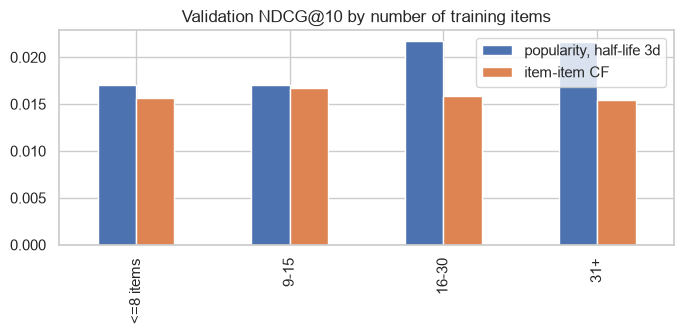

In [10]:
per_user_items = exp.train_matrix.getnnz(axis=1)[eval_users]
bins = pd.cut(per_user_items, [0, 8, 15, 30, np.inf], labels=["<=8 items", "9-15", "16-30", "31+"])
per_user = {name: ev.precision_recall_ndcg(recs, exp.val_matrix[eval_users]) for name, recs in
            {best_baseline: base_recs[best_baseline], "item-item CF": knn_recs}.items()}
seg = pd.DataFrame({name: df["ndcg"].groupby(bins, observed=True).mean() for name, df in per_user.items()})
seg["users"] = pd.Series(bins).value_counts().reindex(seg.index)
display(seg)
seg[[best_baseline, "item-item CF"]].plot(kind="bar", figsize=(7, 3.5), title=f"Validation NDCG@{K} by number of training items")
save_fig("knn_by_user_activity.png")